# Simpson Compost

In [4]:
import numpy as np

def simpson_comp(f, a, b, n):
    h = (b-a)/(2*n)
    S = f(a)
    for i in range(1,n):
        x = a + (2*i)*h
        S += 2*f(x)
    for i in range(0,n):
        x = a + (2*i+1)*h
        S += 4*f(x)
    S += f(b)
    S *= h/3
    return S

In [5]:
def simpson(f,a,b):
  return (b-a)/6. * (f(a) + 4*f((a+b)/2.) + f(b))

def simad(f,a,b,tol=1e-8,hmin=1e-10):
  # intervalo calculado
  S = (a,a)
  # intervalo a ser calculado
  N = (a,b)
  # intervalo ativo
  A = N
  # aprox calculada em [a, b]
  J = 0.
  # aprox calculada em A
  JA = 0.
  # num f eval
  nfe = 0
  # info
  info = 0
  while (S != (a,b)):
    print(S,N,A)
    # tamanho do intervalo
    h = A[1]-A[0]
    while (h > hmin):
      J0 = simpson(f,A[0],A[1])
      JA = simpson(f,A[0],A[0]+h/2.)
      JA += simpson(f,A[0]+h/2.,A[1])
      nfe += 9
      # est erro
      est = np.fabs(J0-JA)/10.
      # criterio de parada
      if (est < tol*h/(b-a)):
        break
      else:
        A = (A[0],A[0]+h/2.)
        h = h/2.
        print("\t",S,N,A,h,est)
        if (h < hmin):
          print("Atencao! h < hmin !")
          info = -1
          break
    J += JA
    S = (a, A[1])
    N = (A[1], b)
    A = N
  return J, nfe, info

   n |        h |   Simpson Composta |  Erro Absoluto | Razão (E_prev/E)
----------------------------------------------------------------------
   2 |   0.7854 |       2.0045597550 |     4.5598e-03 |              ---
   4 |   0.3927 |       2.0002691699 |     2.6917e-04 |            16.94
   8 |   0.1963 |       2.0000165910 |     1.6591e-05 |            16.22
  16 |   0.0982 |       2.0000010334 |     1.0334e-06 |            16.06
  32 |   0.0491 |       2.0000000645 |     6.4530e-08 |            16.01
  64 |   0.0245 |       2.0000000040 |     4.0323e-09 |            16.00
 128 |   0.0123 |       2.0000000003 |     2.5200e-10 |            16.00


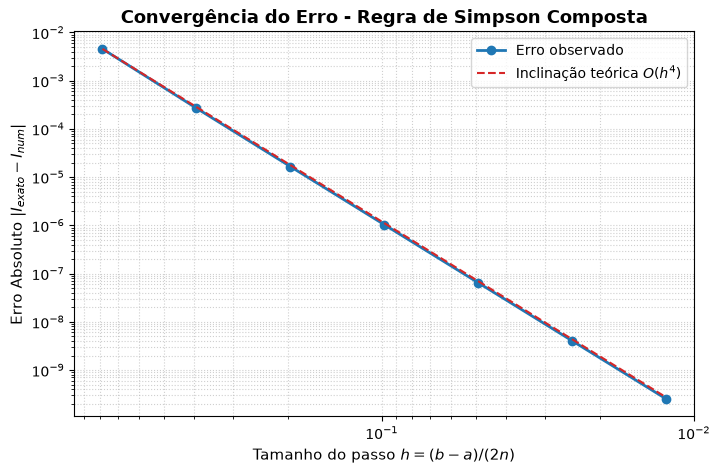

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Função de teste e valor analítico exato
f = np.sin
a, b = 0.0, np.pi
I_exato = 2.0

# 2. Variação de n (número de pares de subintervalos: 2, 4, 8, 16, 32, 64, 128)
ns = [2**k for k in range(1, 8)]
erros = []
hs = []

print(f"{'n':>4} | {'h':>8} | {'Simpson Composta':>18} | {'Erro Absoluto':>14} | {'Razão (E_prev/E)':>16}")
print("-" * 70)

erro_anterior = None
for n in ns:
    h = (b - a) / (2 * n)
    approx = simpson_comp(f, a, b, n)
    erro = abs(I_exato - approx)
    
    razao_str = f"{erro_anterior / erro:.2f}" if erro_anterior else "---"
    print(f"{n:4d} | {h:8.4f} | {approx:18.10f} | {erro:14.4e} | {razao_str:>16}")
    
    hs.append(h)
    erros.append(erro)
    erro_anterior = erro

# 3. Gráfico Log-Log do Erro vs h
plt.figure(figsize=(8, 5))
plt.loglog(hs, erros, 'o-', color='#1f77b4', lw=2, label='Erro observado')

# Linha de referência O(h^4)
ref_h4 = [erros[0] * (h / hs[0])**4 for h in hs]
plt.loglog(hs, ref_h4, '--', color='#d62728', lw=1.5, label=r'Inclinação teórica $O(h^4)$')

plt.title('Convergência do Erro - Regra de Simpson Composta', fontsize=13, fontweight='bold')
plt.xlabel('Tamanho do passo $h = (b - a) / (2n)$', fontsize=11)
plt.ylabel('Erro Absoluto $|I_{exato} - I_{num}|$', fontsize=11)
plt.grid(True, which="both", ls=":", alpha=0.6)
plt.legend(fontsize=10)
plt.gca().invert_xaxis()  # h diminuindo da esquerda para a direita
plt.show()


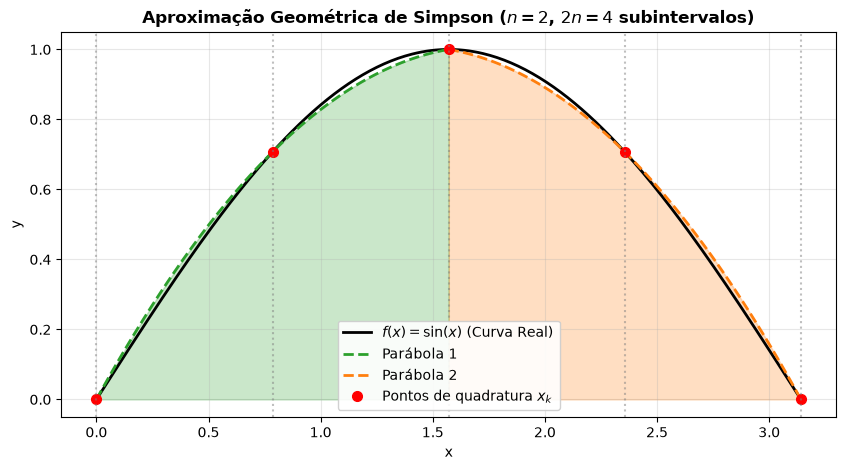

In [7]:
# Configuração para n = 2 (total de 4 subintervalos e 5 pontos)
n = 2
h = (b - a) / (2 * n)
x_pts = np.linspace(a, b, 2 * n + 1)
y_pts = f(x_pts)

# Curva suave de referência
x_fino = np.linspace(a, b, 300)
y_fino = f(x_fino)

plt.figure(figsize=(10, 5))
plt.plot(x_fino, y_fino, 'k-', lw=2, label=r'$f(x) = \sin(x)$ (Curva Real)')

# Ajusta e desenha cada parábola nos intervalos [x_{2i}, x_{2i+2}]
cores = ['#2ca02c', '#ff7f0e']
for i in range(n):
    xi = x_pts[2*i : 2*i + 3]
    yi = y_pts[2*i : 2*i + 3]
    
    # Coeficientes da parábola que passa pelos 3 pontos
    poly = np.polyfit(xi, yi, deg=2)
    
    xp = np.linspace(xi[0], xi[-1], 100)
    yp = np.polyval(poly, xp)
    
    cor = cores[i % len(cores)]
    plt.plot(xp, yp, '--', color=cor, lw=2, label=f'Parábola {i+1}' if n <= 4 else None)
    plt.fill_between(xp, 0, yp, color=cor, alpha=0.25)

# Pontos amostrados
plt.plot(x_pts, y_pts, 'ro', markersize=7, label=r'Pontos de quadratura $x_k$')

# Linhas verticais delimitadoras
for x in x_pts:
    plt.axvline(x, color='gray', linestyle=':', alpha=0.5)

plt.title(f'Aproximação Geométrica de Simpson ($n = {n}$, $2n = {2*n}$ subintervalos)', fontsize=12, fontweight='bold')
plt.xlabel('x')
plt.ylabel('y')
plt.legend(loc='lower center', framealpha=0.9)
plt.grid(True, alpha=0.3)
plt.show()


In [8]:
tolerancias = [1e-2, 1e-4, 1e-6, 1e-8]
print(f"{'Tolerância':>10} | {'Resultado':>14} | {'Erro Real':>12} | {'Nº Avaliações (nfe)':>20}")
print("-" * 65)

for tol in tolerancias:
    res, nfe, info = simad(np.sin, 0, np.pi, tol=tol)
    erro_real = abs(2.0 - res)
    print(f"{tol:10.0e} | {res:14.8f} | {erro_real:12.4e} | {nfe:20d}")


Tolerância |      Resultado |    Erro Real |  Nº Avaliações (nfe)
-----------------------------------------------------------------
(0, 0) (0, 3.141592653589793) (0, 3.141592653589793)
     1e-02 |     2.00455975 |   4.5598e-03 |                    9
(0, 0) (0, 3.141592653589793) (0, 3.141592653589793)
	 (0, 0) (0, 3.141592653589793) (0, 1.5707963267948966) 1.5707963267948966 0.008983534740877453
	 (0, 0) (0, 3.141592653589793) (0, 0.7853981633974483) 0.7853981633974483 0.00021452925180165394
(0, 0.7853981633974483) (0.7853981633974483, 3.141592653589793) (0.7853981633974483, 3.141592653589793)
	 (0, 0.7853981633974483) (0.7853981633974483, 3.141592653589793) (0.7853981633974483, 1.9634954084936207) 1.1780972450961724 0.002060922530189924
	 (0, 0.7853981633974483) (0.7853981633974483, 3.141592653589793) (0.7853981633974483, 1.3744467859455345) 0.5890486225480862 7.141264250989376e-05
(0, 1.3744467859455345) (1.3744467859455345, 3.141592653589793) (1.3744467859455345, 3.141592653589793)